# Python version 3.13.18

In [63]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import os
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import seaborn as sns
import collections
from PIL import Image
from tensorflow.keras import layers, models
from sklearn.metrics import confusion_matrix, classification_report

To first create the CNN NicolasDetectionModel, we have to do the following:

- Create the dataset by combining the not-nicolas and nicolas dataset which is found on the following GitHub Repository:
https://github.com/DrewScatterday/Nicolas_Cage

- Secondly, we must view our data to get an understanding of the following information: the size of the dataset, the demensions and the amount of channels for the images, the amount of classes (2 classes: Nicolas and not Nicolas)

In [47]:
# Cloning the GitHub Repository to gain access to the Nicolas Cage Dataset
!git clone https://github.com/DrewScatterday/Nicolas_Cage.git

fatal: destination path 'Nicolas_Cage' already exists and is not an empty directory.


Confirming the directory for where the images of the dataset is stored

In [48]:
# Define the dataset directory
dataset_path = "/content/Nicolas_Cage/Dataset"

# Display the folders
print(os.listdir(dataset_path))

# Display the contents of Train
print(os.listdir(dataset_path + "/train"))

# Display the contents of Test
print(os.listdir(dataset_path + "/test"))

['train', 'test']
['class1', 'class0']
['class1', 'class0']


Let's see the amount of data that we can work with in order to identify if there is any imbalance present within the dataset

In [49]:
for split in ["train", "test"]:
    for category in ["class0", "class1"]:

        folder = os.path.join(dataset_path, split, category)

        images = os.listdir(folder)

        print(f"{split} - {category}: {len(images)} images")

train - class0: 147 images
train - class1: 143 images
test - class0: 63 images
test - class1: 61 images


Viewing the images we can determine that there is no imbalance between our two classes with there only being a slight difference of 4 images between the Not_Nicolas(class0) and Nicolas(class1) training dataset.

In [50]:
#Creating Constant veriables to set the parameters for the images

# Image dimensions
IMG_HEIGHT = 200
IMG_WIDTH = 200

# Number of images processed at once
BATCH_SIZE = 32

# Reproducibility
SEED = 42

# Dataset paths
train_path = "/content/Nicolas_Cage/train"
test_path = "/content/Nicolas_Cage/test"

In [51]:
#Data Augmentation
train_datagen = ImageDataGenerator(rescale = 1./255,
                                   shear_range = 0.2,
                                   zoom_range = 0.2,
                                   horizontal_flip = True,
                                   validation_split = 0.2)

#Normalization
test_datagen = ImageDataGenerator(rescale = 1./255)

#Alternative code for normalization from lecturer
# Normalize to [0, 1]
#x_train = x_train.astype('float32') / 255.0
#x_test = x_test.astype('float32') / 255.0


# Correcting the paths to point to the correct Dataset subfolder
train_path_dataset = "/content/Nicolas_Cage/Dataset/train"
test_path_dataset = "/content/Nicolas_Cage/Dataset/test"

#Initailizining the training Dataset
training_set = train_datagen.flow_from_directory(train_path_dataset,
    subset="training",
    seed=SEED,
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode="binary")

#Initailizining the validation Dataset
validation_set = train_datagen.flow_from_directory(train_path_dataset,
    subset="validation",
    seed=SEED,
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode="binary")

#Initializing the the test dataset
test_set = test_datagen.flow_from_directory(test_path_dataset,
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode="binary",
    shuffle=False
)

Found 233 images belonging to 2 classes.
Found 57 images belonging to 2 classes.
Found 124 images belonging to 2 classes.


##ImageDataGenerator
Here we want to pre-process our images to get them ready to be fed into the neural network. We use the ImageDataGenerator class inside of Keras. The class takes in a batch of images and applies augmentations like resizing and shearing to the images. It then passes the augmented data to the neural network.

###What is Data Augmentation?:
- According to the super helpful site pyimagesearch, Data augmentation generates “new” training samples from the original ones by applying random jitters and perturbations (but at the same time ensuring that the class labels of the data are not changed).

- It essentially creates new training samples that are slightly "different" than the original training samples

- The goal when applying data augmentation is to increase the generalizability of the model. We use augmentation since we have such a small amount of images and it will help our model generalize new images of Nicolas Cage. Below is a helpful image that explains what augmentation does:

###Parameters
- rescale - we scale the image by a ratio of 1./255
- shear range - We specify a range for our image to be sheared or shifted a certain direction
- zoom range - We specify a range for our image to be randomly zoomed in on
- horizontal_flip - Randomly flip inputs horizontally
- IMAGE_HEIGHT/ IMAGE_WIDTH - is the size of our input images, every image will be resized 200x200
- BATCH_SIZE - we loop over our images in batches so we make our batch size 32 images big
- class_mode - we set this to “binary” since we have only two classes to predict Nicolas Cage in an image or not

**HELPFUL NOTES ON DATA AUGMENTATION PROVIDED BY https://github.com/DrewScatterday/Nicolas_Cage **


In [52]:
#Mapping the dictionary values of the dataset to be more readable
class_mapping = {
    0: "Not Nicolas Cage",
    1: "Nicolas Cage"
}

print(class_mapping)

{0: 'Not Nicolas Cage', 1: 'Nicolas Cage'}


### Objectives when conducting Image EDA

- How many images are available in each class?
- Are the classes balanced?
- What do the images look like?
- Are there poor-quality, corrupted or irrelevant images?
- Are the images sufficiently diverse?

(List provided by ChatGPT)

In [53]:
#Inspecting Shapes
print("Training images:", training_set.image_shape)
print("Test images:", test_set.image_shape)
print("Training labels:", training_set.classes.shape)

Training images: (200, 200, 3)
Test images: (200, 200, 3)
Training labels: (233,)


We can see that the images were already augmented to be 200 X 200 when we created the dataset.

There is a total of 290 images available in the training set

Not Nicolas Cage: 118 images
Nicolas Cage: 115 images


/tmp/ipykernel_2594/2072033541.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=labels, y=counts, ax=axes[0], palette="cool")


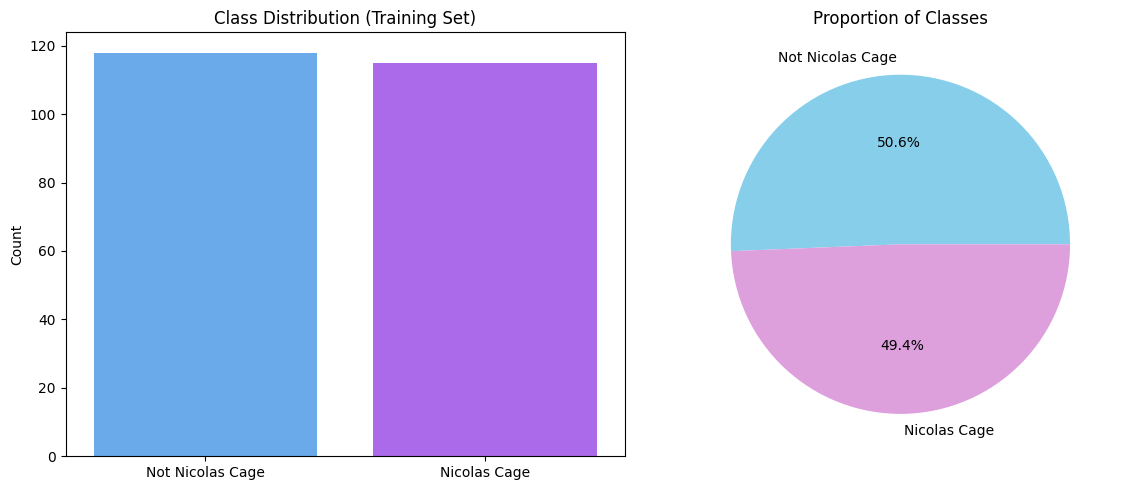

In [54]:
# Inspecting the distribution of each class in the training set

# Count the occurrences of each class index in the training set
class_counts = collections.Counter(training_set.classes)

# Map the indices to our readable labels
labels = [class_mapping[0], class_mapping[1]]
counts = [class_counts[0], class_counts[1]]

print(f"{labels[0]}: {counts[0]} images")
print(f"{labels[1]}: {counts[1]} images")

# Plotting the target distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Bar plot for class distribution
sns.barplot(x=labels, y=counts, ax=axes[0], palette="cool")
axes[0].set_title('Class Distribution (Training Set)')
axes[0].set_ylabel('Count')

# Percentage pie chart
axes[1].pie(counts, labels=labels, autopct='%1.1f%%', colors=['skyblue', 'plum'])
axes[1].set_title('Proportion of Classes')

plt.tight_layout()
plt.show()

Viewing these graphs it is clear that there is no class imbalance within our dataset. This means that it isnt necessary to take steps to correct the balance.

**Seaborn Colour Pallete  (Personal use)**
https://www.practicalpythonfordatascience.com/ap_seaborn_palette

### Let's view a sample of the images that is within the dataset.
- To ensure that the images have been labeled correctly
- To ensure the quality, diversity and proper formatting of the images

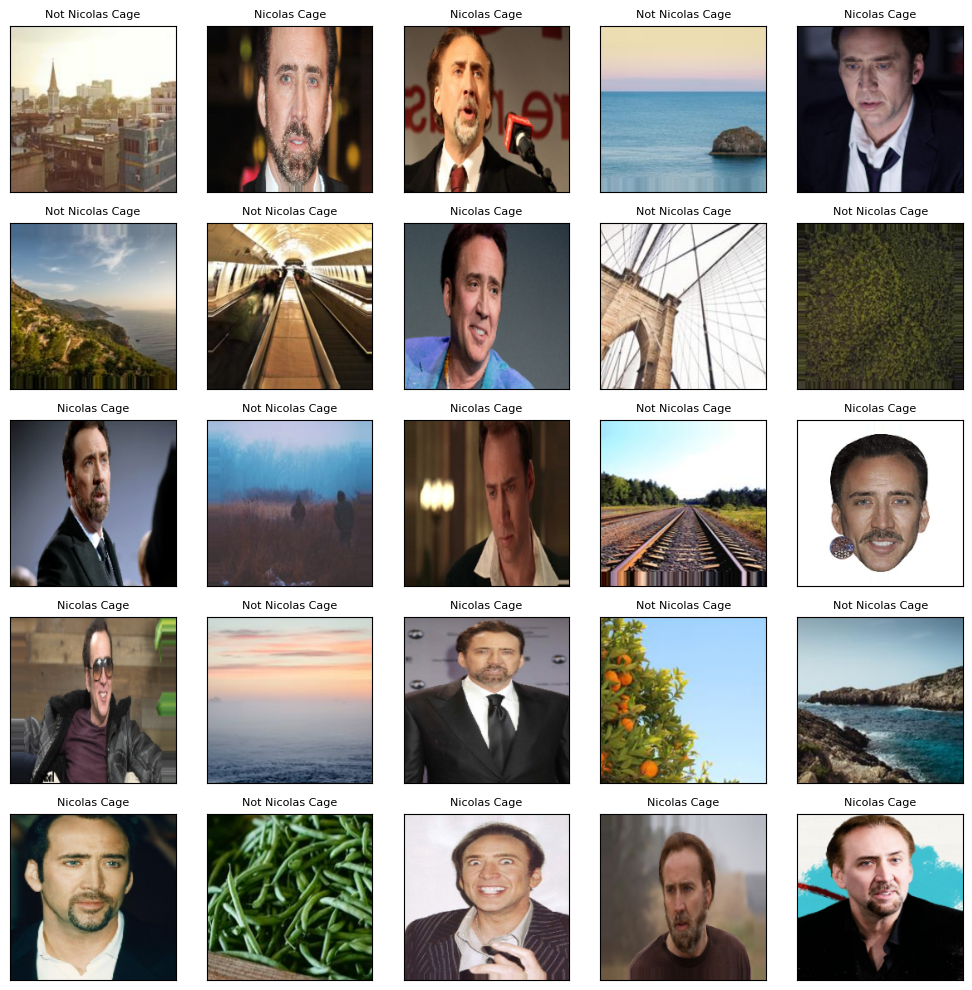

In [55]:
# Get the first batch of images and labels from the DirectoryIterator
images_batch, labels_batch = next(training_set)

# We have a batch of 32 images, so we can display up to 32 of them
plt.figure(figsize=(10, 10))

for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)

    # Display the individual image from the batch
    plt.imshow(images_batch[i])

    # Retrieve the label index and map it to our class name
    label_index = int(labels_batch[i])
    plt.title(class_mapping[label_index], fontsize=8)

plt.tight_layout()
plt.show()

In [56]:
from PIL import Image
import os

# Correcting the path to use train_path_dataset
folder = os.path.join(train_path_dataset, "class0")

for filename in os.listdir(folder)[:10]:
    image_path = os.path.join(folder, filename)
    try:
        img = Image.open(image_path)
        print(filename, img.size, img.format)
    except Exception as e:
        print("Unable to read:", filename, e)

not_nicolas_140.jpg (200, 200) JPEG
not_nicolas_107.jpg (200, 200) JPEG
not_nicolas_28.jpg (200, 200) JPEG
not_nicolas_8.jpg (200, 200) JPEG
not_nicolas_96.jpg (200, 200) JPEG
not_nicolas_141.jpg (200, 200) JPEG
not_nicolas_12.jpg (200, 200) JPEG
not_nicolas_9.jpg (200, 200) JPEG
not_nicolas_133.jpg (200, 200) JPEG
not_nicolas_2.jpg (200, 200) JPEG


In [57]:
#Code provided by GoogleGemini
#Scans images within dataset to determine whether they are corrupted and lists them

corrupted_count = 0
corrupted_files = []

# Walk through the dataset directory to scan all images
for root, dirs, files in os.walk(dataset_path):
    for filename in files:
        if filename.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp', '.gif', '.tiff')):
            image_path = os.path.join(root, filename)
            try:
                with Image.open(image_path) as img:
                    img.verify()  # Verifies the file integrity without fully loading image data
            except Exception as e:
                print(f"Corrupted or unreadable image found: {image_path} | Error: {e}")
                corrupted_files.append(image_path)
                corrupted_count += 1

print("\n--- Verification Summary ---")
print(f"Total corrupted images found: {corrupted_count}")
if corrupted_count > 0:
    print("List of corrupted files:", corrupted_files)


--- Verification Summary ---
Total corrupted images found: 0


Luckily there where no corrupted images found in this dataset which is important due to its small sample size

## **Let's see the diversity of the images within the dataset**

**What aspects of image diversity should you investigate in this dataset? **

- Different Facial expressions (smiling, serious, angry)
- Different ages and hairstyles
- Different perspectives, such as frontal, side-profile and three-quarter views
- Different Lighting
- Different backgrounds and environments
- Image quality

(List provided by ChatGPT)

Lets view the Image grid again and consider the checklist whilst evaluating the images.

## Build CNN

###Key Concepts (provided by lecturer)

- Filters (Kernels): Small matrices (e.g., 3×3) that slide across the image. Each filter learns to detect one pattern. With 32 filters in layer 1, the network learns 32 different feature detectors.

- Stride: How far the filter moves each step. Stride=1 means pixel-by-pixel. Stride=2 skips every other position, reducing output size.

- Padding: Adding zeros around the border. "Same" padding keeps spatial dimensions unchanged; "valid" (no padding) shrinks them.

- ReLU: f(x) = max(0, x). Fast to compute, avoids vanishing gradients, and introduces the nonlinearity CNNs need .

- MaxPooling: Takes the maximum value in each 2×2 region. Reduces computation and provides small translation invariance — a feature detected slightly off-center still triggers the same pooled activation .

- Flatten: Converts the 3D tensor (5, 5, 64) into a 1D vector of 1600 values. The Dense layers require 1D input.

- Dropout: During training, randomly "drops" neurons with probability 0.5. This prevents coadaptation — neurons can't rely on specific other neurons always being present .

- Softmax: Converts raw scores (logits) into probabilities that sum to 1. The class with highest probability is the prediction.

**What should you keep in mind when building CNN in regards to writing the code?**

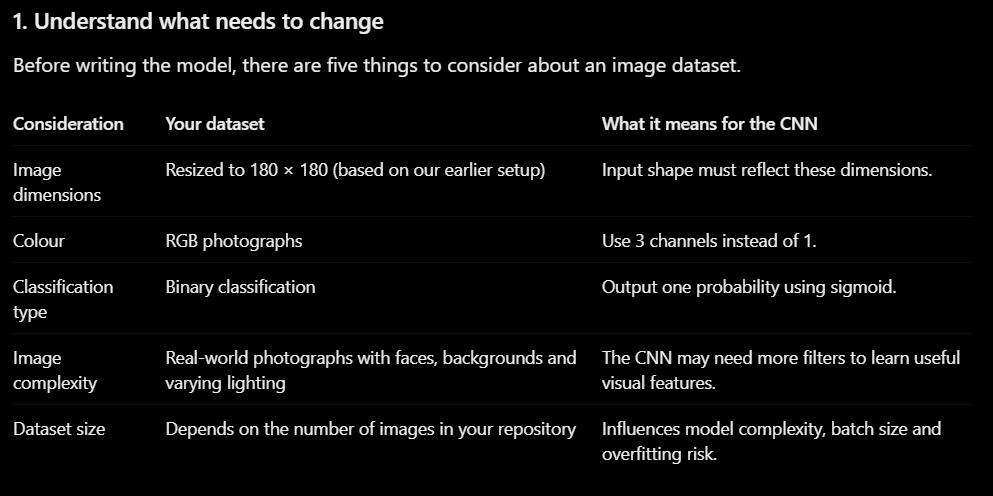


In [58]:
cnn_model = models.Sequential([
    # Input layer: 200X200 RGB images
    layers.Input(shape=(200, 200, 3)),

    # 200,200: image height, width
    # 3: colour channel (red,green and blue) for greyscale = 1

    # First convolutional block
    layers.Conv2D(filters=32, kernel_size=(3, 3), activation='relu'),
    layers.MaxPooling2D(pool_size=(2, 2)),

    # Second convolutional block
    layers.Conv2D(filters=64, kernel_size=(3, 3), activation='relu'),
    layers.MaxPooling2D(pool_size=(2, 2)),

    # Third convolutional block
    layers.Conv2D(filters=128, kernel_size=(3, 3), activation='relu'),
    layers.MaxPooling2D(pool_size=(2, 2)),

    # The more complex the images are, the more convolutional layers should be added
    #A convolutional layer applies filters (also called kernels) to an image to identify patterns.
    # Deeper layers can learn more complex patterns, such as facial features and combinations of shapes.

    # Classification layers
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),

    # Binary output
    layers.Dense(1, activation='sigmoid')

    #Softmax is appropriate for a dataset with 10 possible classes.
    #layers.Dense(10, activation='softmax')
])

cnn_model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_9 (Conv2D)               │ (None, 198, 198, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 99, 99, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 97, 97, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 48, 48, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 46, 46, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 23, 23, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,889 (429.25 KB)

 Trainable params: 109,889 (429.25 KB)

 Non-trainable params: 0 (0.00 B)

**Why use GlobalAveragePooling2D instead of Flatten?**

Flatten() takes every value from every feature map and converts them into a long vector. With larger images, this can create a very large number of parameters in the following dense layer.

GlobalAveragePooling2D() calculates the average value of each feature map instead. This gives the dense layer a much smaller input, reducing the number of parameters and potentially reducing overfitting.

It is not necessarily always better than flattening, but it is a sensible starting point for your dataset.

### Compiling CNN model

In [59]:
cnn_model.compile(
    optimizer='adam', # uses Adam with default learning rate.
    loss='binary_crossentropy', #Binary values (2 Classes)
    metrics=['accuracy', 'precision', 'recall'] #tracks classification accuracy during training.

    # loss='sparse_categorical_crossentropy' expects integer labels (not one-hot).
)

## Training the model

In [64]:
cnn_history = cnn_model.fit(
    training_set,
    epochs=25, # goes the entire dataset 15 times
    validation_data=validation_set,
    verbose=1
)

Epoch 1/25
8/8 ━━━━━━━━━━━━━━━━━━━━ 6s 783ms/step - accuracy: 0.8584 - loss: 0.3606 - precision: 0.8534 - recall: 0.8609 - val_accuracy: 0.8596 - val_loss: 0.3474 - val_precision: 0.7941 - val_recall: 0.9643
Epoch 2/25
8/8 ━━━━━━━━━━━━━━━━━━━━ 4s 480ms/step - accuracy: 0.8455 - loss: 0.3759 - precision: 0.8624 - recall: 0.8174 - val_accuracy: 0.8947 - val_loss: 0.3473 - val_precision: 0.8235 - val_recall: 1.0000
Epoch 3/25
8/8 ━━━━━━━━━━━━━━━━━━━━ 4s 469ms/step - accuracy: 0.8326 - loss: 0.3991 - precision: 0.8455 - recall: 0.8087 - val_accuracy: 0.8246 - val_loss: 0.4280 - val_precision: 0.7368 - val_recall: 1.0000
Epoch 4/25
8/8 ━━━━━━━━━━━━━━━━━━━━ 5s 584ms/step - accuracy: 0.8326 - loss: 0.3627 - precision: 0.8393 - recall: 0.8174 - val_accuracy: 0.8772 - val_loss: 0.3874 - val_precision: 0.8000 - val_recall: 1.0000
Epoch 5/25
8/8 ━━━━━━━━━━━━━━━━━━━━ 4s 517ms/step - accuracy: 0.8541 - loss: 0.3691 - precision: 0.8584 - recall: 0.8435 - val_accuracy: 0.8421 - val_loss: 0.3566 - val

### Model evaluation

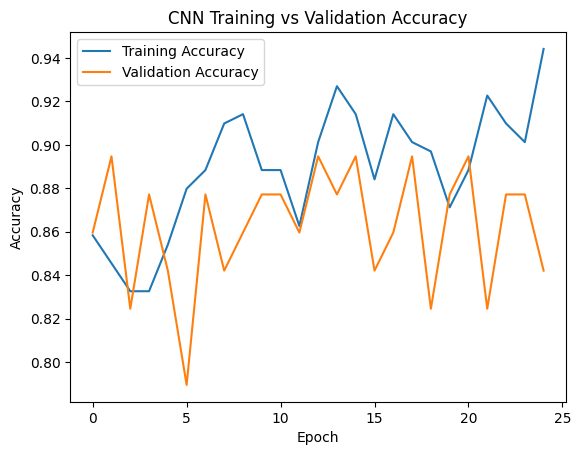

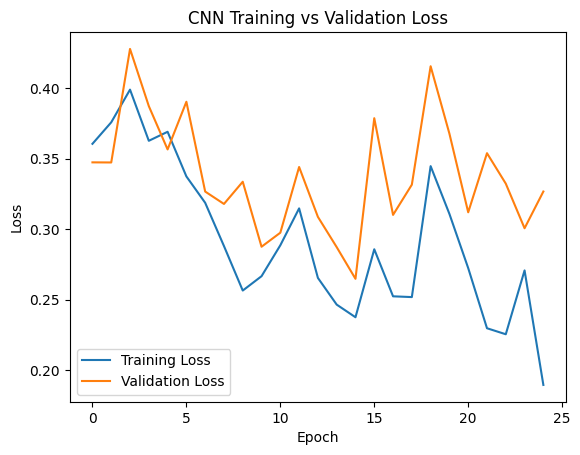

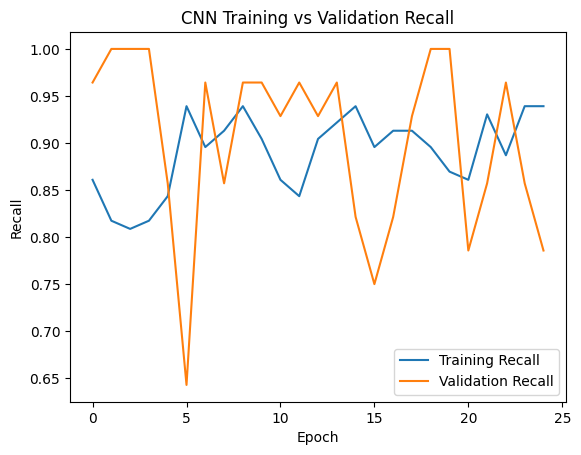

In [65]:
# Accuracy
plt.plot(cnn_history.history['accuracy'], label='Training Accuracy')
plt.plot(cnn_history.history['val_accuracy'], label='Validation Accuracy')

plt.title('CNN Training vs Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

# Loss
plt.plot(cnn_history.history['loss'], label='Training Loss')
plt.plot(cnn_history.history['val_loss'], label='Validation Loss')

plt.title('CNN Training vs Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

# Recall
plt.plot(cnn_history.history['recall'], label='Training Recall')
plt.plot(cnn_history.history['val_recall'], label='Validation Recall')

plt.title('CNN Training vs Validation Recall')
plt.xlabel('Epoch')
plt.ylabel('Recall')
plt.legend()
plt.show()

These graphs indicates that the accuracy is improving but not stagnating meaning that it learning and not overfitting. The loss is also decreasing

In [67]:
eval_results = cnn_model.evaluate(
    test_set,
    verbose=1
)

# Unpack the metrics returned by evaluate()
test_loss = eval_results[0]
test_acc = eval_results[1]
test_precision = eval_results[2]
test_recall = eval_results[3]

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")
print(f"Test Precision: {test_precision:.4f}")
print(f"Test Recall: {test_recall:.4f}")

4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 149ms/step - accuracy: 0.8952 - loss: 0.2600 - precision: 0.9138 - recall: 0.8689
Test Loss: 0.2600
Test Accuracy: 0.8952
Test Precision: 0.9138
Test Recall: 0.8689


In [68]:
# Generate predicted probabilities
y_pred_probs = cnn_model.predict(test_set)

# Convert probabilities into predicted class labels
y_pred = (y_pred_probs.ravel() >= 0.5).astype(int)

# Obtain the actual labels from the test set
y_true = test_set.classes

4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 238ms/step


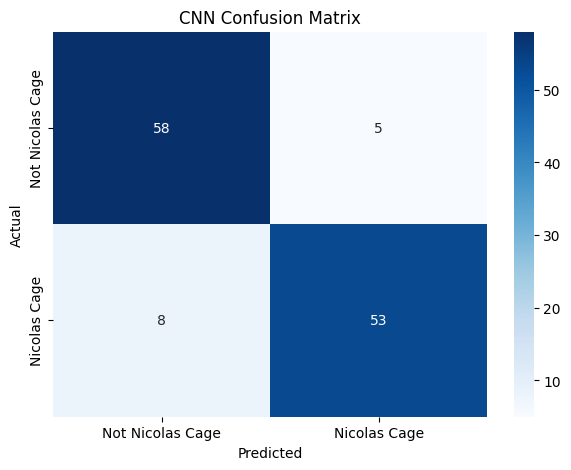

In [70]:
# Generate confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

# Display confusion matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Not Nicolas Cage', 'Nicolas Cage'],
    yticklabels=['Not Nicolas Cage', 'Nicolas Cage']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('CNN Confusion Matrix')
plt.show()

This Confusion Matrix shows that it has a really high probability of correctly identifying whether an image has Nicolas Cage present

In [72]:
from sklearn.metrics import classification_report

# Generate classification report
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=['Not Nicolas Cage', 'Nicolas Cage'],
    zero_division=0
))

                  precision    recall  f1-score   support

Not Nicolas Cage       0.88      0.92      0.90        63
    Nicolas Cage       0.91      0.87      0.89        61

        accuracy                           0.90       124
       macro avg       0.90      0.89      0.89       124
    weighted avg       0.90      0.90      0.90       124



#### **Precision**
There is a high precision for both classes which means the model makes fewer incorrect identifications.

#### **Recall**
High recall means the model successfully identifies most Nicolas Cage images.

#### **F1-Score**

High F1-score indicates a good balance between precision and recall.


### An Image grid

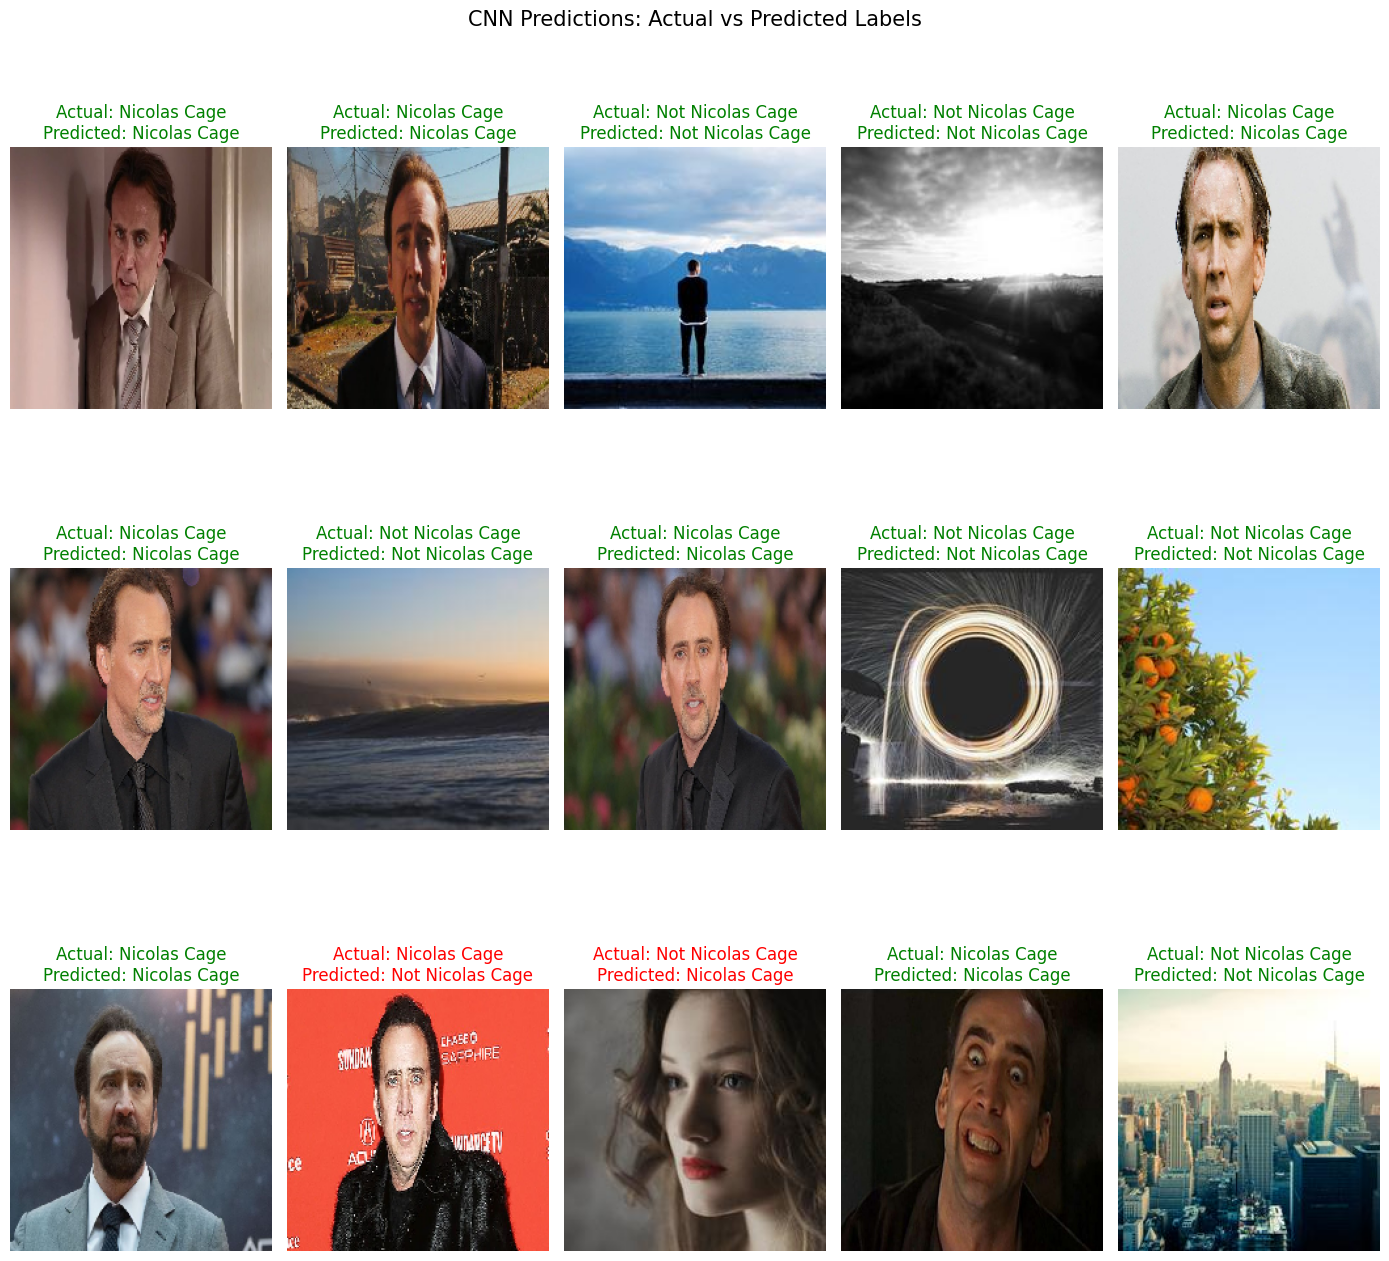

In [78]:
# Class names
class_names = ['Not Nicolas Cage', 'Nicolas Cage']

# Select random images from the test dataset
np.random.seed(24)
indices = np.random.choice(
    len(y_true),
    size=min(15, len(y_true)),
    replace=False
)

# Display image grid
fig, axes = plt.subplots(3, 5, figsize=(14, 14))
axes = axes.flatten()

for i, idx in enumerate(indices):

    # Load the original image
    image_path = test_set.filepaths[idx]

    from tensorflow.keras.utils import load_img
    image = load_img(
        image_path,
        target_size=(IMG_HEIGHT, IMG_WIDTH)
    )

    # Actual and predicted labels
    actual_label = class_names[y_true[idx]]
    predicted_label = class_names[y_pred[idx]]

    # Check whether prediction is correct
    correct = y_true[idx] == y_pred[idx]

    # Display image
    axes[i].imshow(image)
    axes[i].set_title(
        f"Actual: {actual_label}\nPredicted: {predicted_label}",
        color='green' if correct else 'red',
        fontsize=12
    )

    axes[i].axis('off')

# Hide unused subplots
for j in range(i + 1, len(axes)):
    axes[j].axis('off')

plt.suptitle(
    'CNN Predictions: Actual vs Predicted Labels',
    fontsize=15
)

plt.tight_layout()
plt.show()

## Notes for POE
- Ensure that the EDA and preprocessing is done before Data Augmentation

###Links to CNN resources (personal use)
https://www.kaggle.com/code/pavansanagapati/a-simple-cnn-model-beginner-guide
https://github.com/DrewScatterday/Nicolas_Cage/blob/master/Nic_Cage_Explanation.ipynb
https://www.youtube.com/watch?v=EDH9HmfjyQU
https://mystudies.iie.edu.za/d2l/le/lessons/97490/topics/7178878